# Giai đoạn 5: Triển khai Ba Chế độ Quyết định (Heuristic, Supervised, Adaptive)

**Dự án:** Tái hiện kiến trúc Agentic cho bài toán Phân bổ Vị trí Lưu trữ Động (SLAP).  
**Paper tham chiếu:** Rodrigo Furlan de Assis et al. (2026), *Agentic Architecture for Progressive Autonomous Storage Location Assignment in Warehouses*, Procedia CIRP, 146, 643–648.

---

### Mục tiêu Kỹ thuật của Giai đoạn 5:
1. **Kiến trúc Vòng lặp Agentic Thống nhất:**
   $$\text{Perception} \longrightarrow \text{Candidate Set} \longrightarrow \text{Evaluation} \longrightarrow \text{Decision} \longrightarrow \text{Supervision} \longrightarrow \text{Action} \longrightarrow \text{Learning}$$
2. **Triển khai Ba Chế độ Quyết định:**
   - **Mode 1 - Heuristic:** Tối đa hóa điểm số Heuristic:
     $$Score_l = -\Delta MI_l + \gamma \cdot \mathbb{1}(s_t \text{ đã có tại } l)$$
     kết hợp cơ chế Look-Ahead Split phân hoạch nguyên tối ưu.
   - **Mode 2 - Supervised:** Tự chủ có điều kiện (Conditional Autonomy) với cổng phê duyệt tự động:
     - Tự động duyệt (*Auto-approved*) nếu $\Delta MI \le 0$ (gom hàng).
     - Chuyển trạng thái chờ duyệt (*Pending Manual*) nếu $\Delta MI > 0$ (tăng hỗn tạp, cần người giám sát xác nhận). Trạng thái kho giữ nguyên 100%.
   - **Mode 3 - Adaptive:** Hàm utility đa tiêu chí $U_l = w^T x_l$ kết hợp vector 6 chiều và cập nhật trọng số online theo quy tắc gradient descent:
     $$w \leftarrow w - \eta \left[ 2 (\hat{U}_t - r_t) \bar{x}_t + \lambda w \right]$$
     với $\eta = 0.05$, $\lambda = 0.01$, $\epsilon = 0.1$.
3. **Thử nghiệm Thực tế trên Chuỗi Sự kiện Pilot (50 Events):**
   - Chạy cả 3 chế độ trên cùng một trạng thái kho ban đầu và cùng chuỗi 50 sự kiện.
   - Theo dõi quỹ đạo biến thiên Mixing Index, tỷ lệ phê duyệt, sự tiến hóa của trọng số và hiệu năng thực thi.


In [1]:
import os
import sys
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập đường dẫn import src
repo_root = os.path.abspath("..")
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from src.model.warehouse_state import WarehouseState
from src.model.metrics import calculate_warehouse_metrics
from src.agents import HeuristicAgent, SupervisedAgent, AdaptiveAgent
from src.simulation.runner import SimulationRunner

# Cấu hình thẩm mỹ trực quan
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.sans-serif": "DejaVu Sans",
    "figure.titlesize": 14,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "figure.dpi": 150,
})

os.makedirs("../outputs/figures", exist_ok=True)
os.makedirs("../outputs/tables", exist_ok=True)
os.makedirs("../outputs/logs", exist_ok=True)
os.makedirs("../outputs/metrics", exist_ok=True)

print("Environment setup successful. All Phase 5 agent modules imported.")


Environment setup successful. All Phase 5 agent modules imported.


## 1. Nạp Môi trường & Chuẩn bị Chuỗi Sự kiện Pilot

Nạp snapshot kho thực tế sau giải phóng 20% dung lượng (`warehouse_slots_state_z34.csv`) và trích xuất 50 sự kiện đầu tiên từ chuỗi sự kiện chuẩn (`inbound_events.csv`).


In [2]:
# 1. Nạp snapshot kho ban đầu
slots_df = pd.read_csv("../data/processed/warehouse_slots_state_z34.csv")
base_warehouse = WarehouseState.from_long_dataframe(slots_df)

# 2. Nạp chuỗi sự kiện nhập hàng
all_events_df = pd.read_csv("../data/processed/inbound_events.csv")
pilot_events_df = all_events_df.iloc[:50].copy()
pilot_events = pilot_events_df.to_dict(orient="records")

# 3. Tính metrics khởi tạo
initial_metrics = calculate_warehouse_metrics(base_warehouse)

print("=== THÔNG SỐ KHỞI TẠO MÔ PHỎNG PILOT (50 SỰ KIỆN) ===")
print(f"Tổng số vị trí lưu trữ: {base_warehouse.total_locations()} vị trí (Tầng z in {{3, 4}})")
print(f"Sức chứa đang sử dụng:   {base_warehouse.total_occupied_units()} units (Tỷ lệ lấp đầy: {initial_metrics['occupancy_rate_pct']}%)")
print(f"Dung lượng trống:       {base_warehouse.free_capacity()} units")
print(f"Mixing Index ban đầu:   {initial_metrics['average_mi']:.4f}")
print(f"Số sự kiện pilot:       {len(pilot_events)} sự kiện")
print(f"Tổng lượng hàng nhập:   {pilot_events_df['quantity'].sum()} units (TB: {pilot_events_df['quantity'].mean():.2f} units/event)")


=== THÔNG SỐ KHỞI TẠO MÔ PHỎNG PILOT (50 SỰ KIỆN) ===
Tổng số vị trí lưu trữ: 600 vị trí (Tầng z in {3, 4})
Sức chứa đang sử dụng:   8640 units (Tỷ lệ lấp đầy: 80.0%)
Dung lượng trống:       2160 units
Mixing Index ban đầu:   0.9015
Số sự kiện pilot:       50 sự kiện
Tổng lượng hàng nhập:   75 units (TB: 1.50 units/event)


## 2. Chế độ 1 – Heuristic Agent (Greedy MI Minimization + Look-Ahead)

**Nguyên lý vận hành:**
- Quét các ứng viên vị trí thỏa sức chứa $a_{l,t} \ge u_t$ và ngưỡng an toàn $MI_l(S_{t+1}) \le \tau = 0.95$.
- Nếu cần, chia lô nhìn trước (Look-Ahead Split) qua 2 vị trí để tìm cơ hội gom hàng tốt hơn.
- Chọn phương án có điểm số $Score_l = -\Delta MI_l + \gamma \cdot \mathbb{1}(s_t \in l)$ cao nhất và tự động thực thi.


=== KẾT QUẢ HEURISTIC AGENT (50 SỰ KIỆN) ===
Số hành động thực thi:   50 / 50 (100.0%)
Số lần chia lô (Split):  15 lần
Delta MI trung bình:     -0.1063
Mixing Index kết thúc:   0.8926 (Ban đầu: 0.9015)
Thời gian xử lý TB:      13.54 ms/event


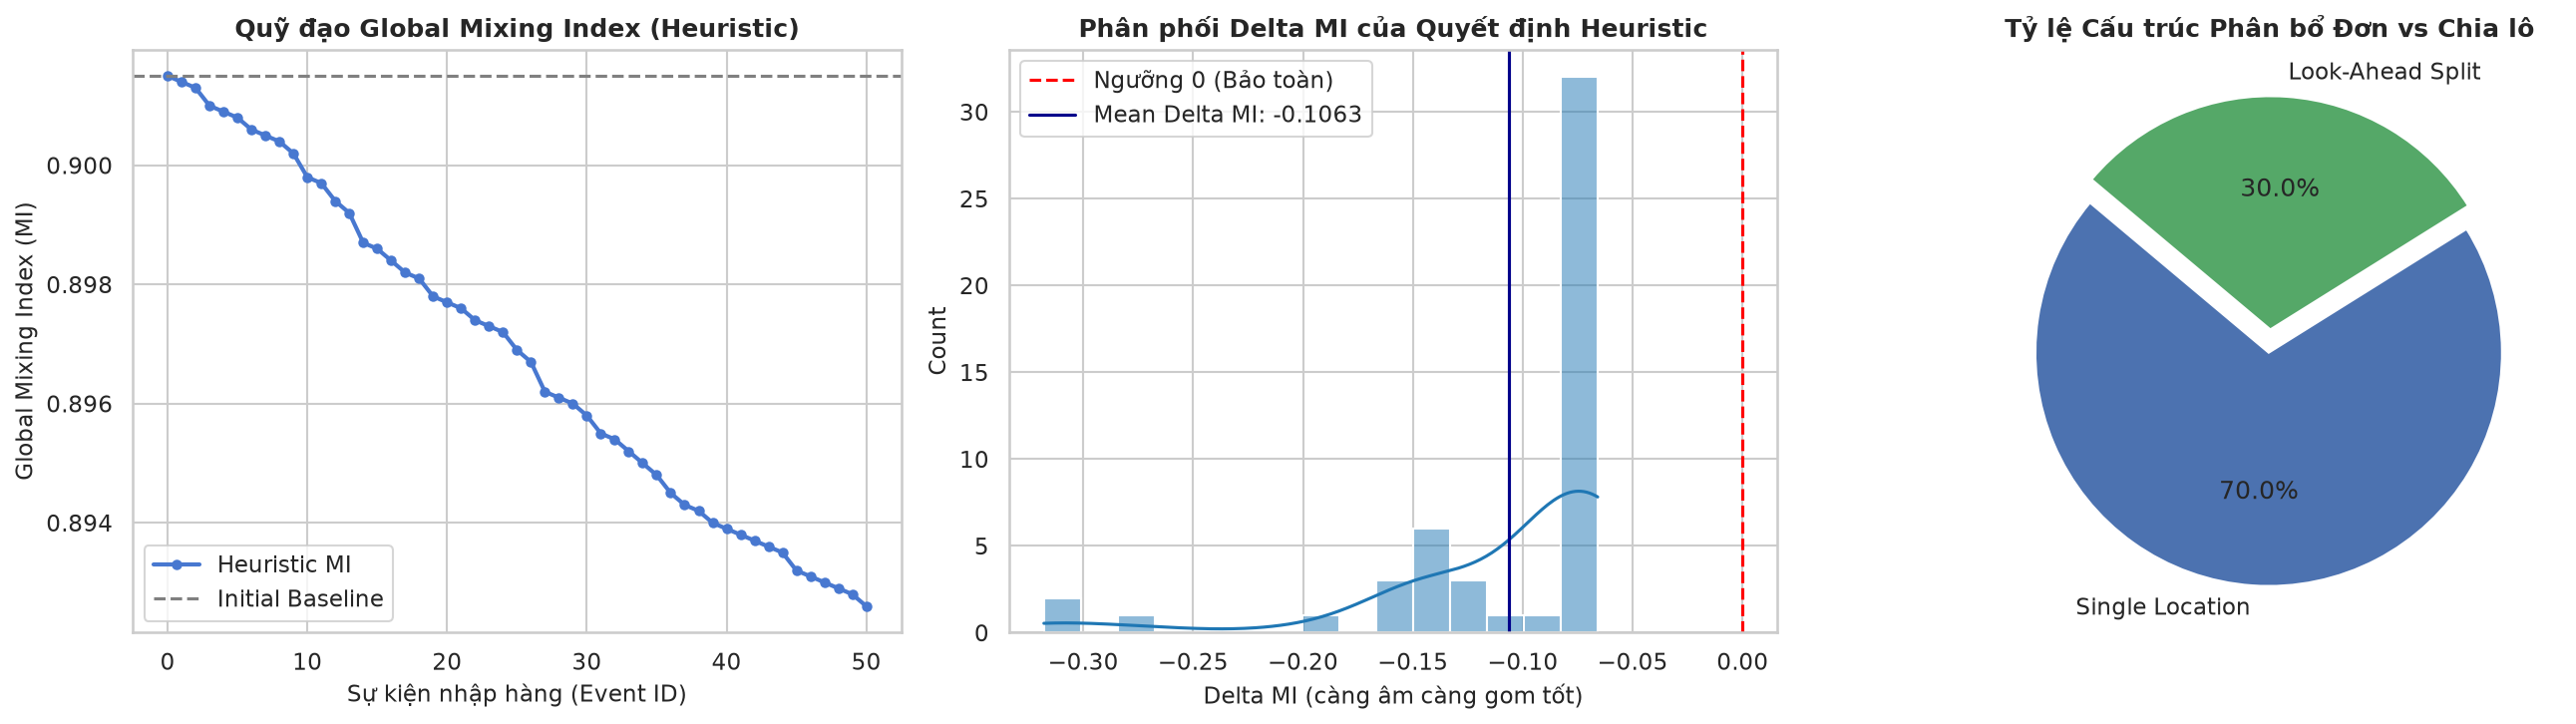

In [3]:
# Khởi tạo Heuristic Agent
heuristic_agent = HeuristicAgent(gamma=0.1, tau=0.95, top_k=30, allow_split=True)

# Chạy mô phỏng pilot với SimulationRunner
heuristic_runner = SimulationRunner(
    agent=heuristic_agent,
    initial_state=base_warehouse,
    events=pilot_events,
    snapshot_interval=1,
    output_dir="../outputs"
)
heuristic_logger = heuristic_runner.run(show_progress=False)

df_actions_h = pd.DataFrame(heuristic_logger.action_logs)
df_metrics_h = pd.DataFrame(heuristic_logger.metric_snapshots)

print(f"=== KẾT QUẢ HEURISTIC AGENT ({len(df_actions_h)} SỰ KIỆN) ===")
print(f"Số hành động thực thi:   {sum(df_actions_h['status'] == 'executed')} / {len(df_actions_h)} ({sum(df_actions_h['status'] == 'executed')/len(df_actions_h)*100:.1f}%)")
print(f"Số lần chia lô (Split):  {df_actions_h['is_split'].sum()} lần")
print(f"Delta MI trung bình:     {df_actions_h['delta_mi'].mean():.4f}")
print(f"Mixing Index kết thúc:   {df_metrics_h['average_mi'].iloc[-1]:.4f} (Ban đầu: {df_metrics_h['average_mi'].iloc[0]:.4f})")
print(f"Thời gian xử lý TB:      {df_actions_h['runtime_ms'].mean():.2f} ms/event")

# Vẽ đồ thị kết quả Heuristic
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Quỹ đạo Global MI
axes[0].plot(df_metrics_h["event_id"], df_metrics_h["average_mi"], "b-o", linewidth=2, markersize=4, label="Heuristic MI")
axes[0].axhline(df_metrics_h["average_mi"].iloc[0], color="gray", linestyle="--", label="Initial Baseline")
axes[0].set_title("Quỹ đạo Global Mixing Index (Heuristic)", fontweight="bold")
axes[0].set_xlabel("Sự kiện nhập hàng (Event ID)")
axes[0].set_ylabel("Global Mixing Index (MI)")
axes[0].legend()

# Subplot 2: Phân phối Delta MI
sns.histplot(df_actions_h["delta_mi"], bins=15, kde=True, ax=axes[1], color="tab:blue")
axes[1].axvline(0.0, color="red", linestyle="--", label="Ngưỡng 0 (Bảo toàn)")
axes[1].axvline(df_actions_h["delta_mi"].mean(), color="darkblue", linestyle="-", label=f"Mean Delta MI: {df_actions_h['delta_mi'].mean():.4f}")
axes[1].set_title("Phân phối Delta MI của Quyết định Heuristic", fontweight="bold")
axes[1].set_xlabel("Delta MI (càng âm càng gom tốt)")
axes[1].legend()

# Subplot 3: Tỷ lệ Single vs Split
split_counts = df_actions_h["is_split"].value_counts()
axes[2].pie(
    [split_counts.get(False, 0), split_counts.get(True, 0)],
    labels=["Single Location", "Look-Ahead Split"],
    autopct="%1.1f%%",
    colors=["#4c72b0", "#55a868"],
    startangle=140,
    explode=(0.05, 0.05)
)
axes[2].set_title("Tỷ lệ Cấu trúc Phân bổ Đơn vs Chia lô", fontweight="bold")

plt.tight_layout()
plt.savefig("../outputs/figures/phase5_heuristic_pilot_trajectory.png", dpi=300)
plt.show()


## 3. Chế độ 2 – Supervised Agent (Cổng An toàn & Phê duyệt Giám sát)

**Nguyên lý vận hành:**
- Kế thừa bộ đánh giá của Heuristic.
- Áp dụng cổng an toàn tự chủ (*Safety Approval Gate*):
  - **Tự động chấp thuận (Auto-approve):** Nếu $\Delta MI \le 0$ (hành động gom hàng hoặc không làm xấu hỗn tạp kho).
  - **Chuyển trạng thái chờ (Pending Manual):** Nếu $\Delta MI > 0$, hành động làm tăng độ hỗn tạp sẽ không được tự động thực thi. Trạng thái kho được giữ nguyên 100%.
- Thử nghiệm độ nhạy: So sánh chính sách chính (`pending_manual`) với chính sách giả lập người vận hành duyệt tất cả (`always_approve`).


=== KẾT QUẢ SUPERVISED AGENT ===
Tự động duyệt (Auto-approved, Delta MI <= 0): 50 (100.0%)
Chuyển trạng thái chờ (Pending, Delta MI > 0):  0 (0.0%)
MI kết thúc (Chính sách Pending):             0.8926
MI kết thúc (Chính sách Always Approve):      0.8926


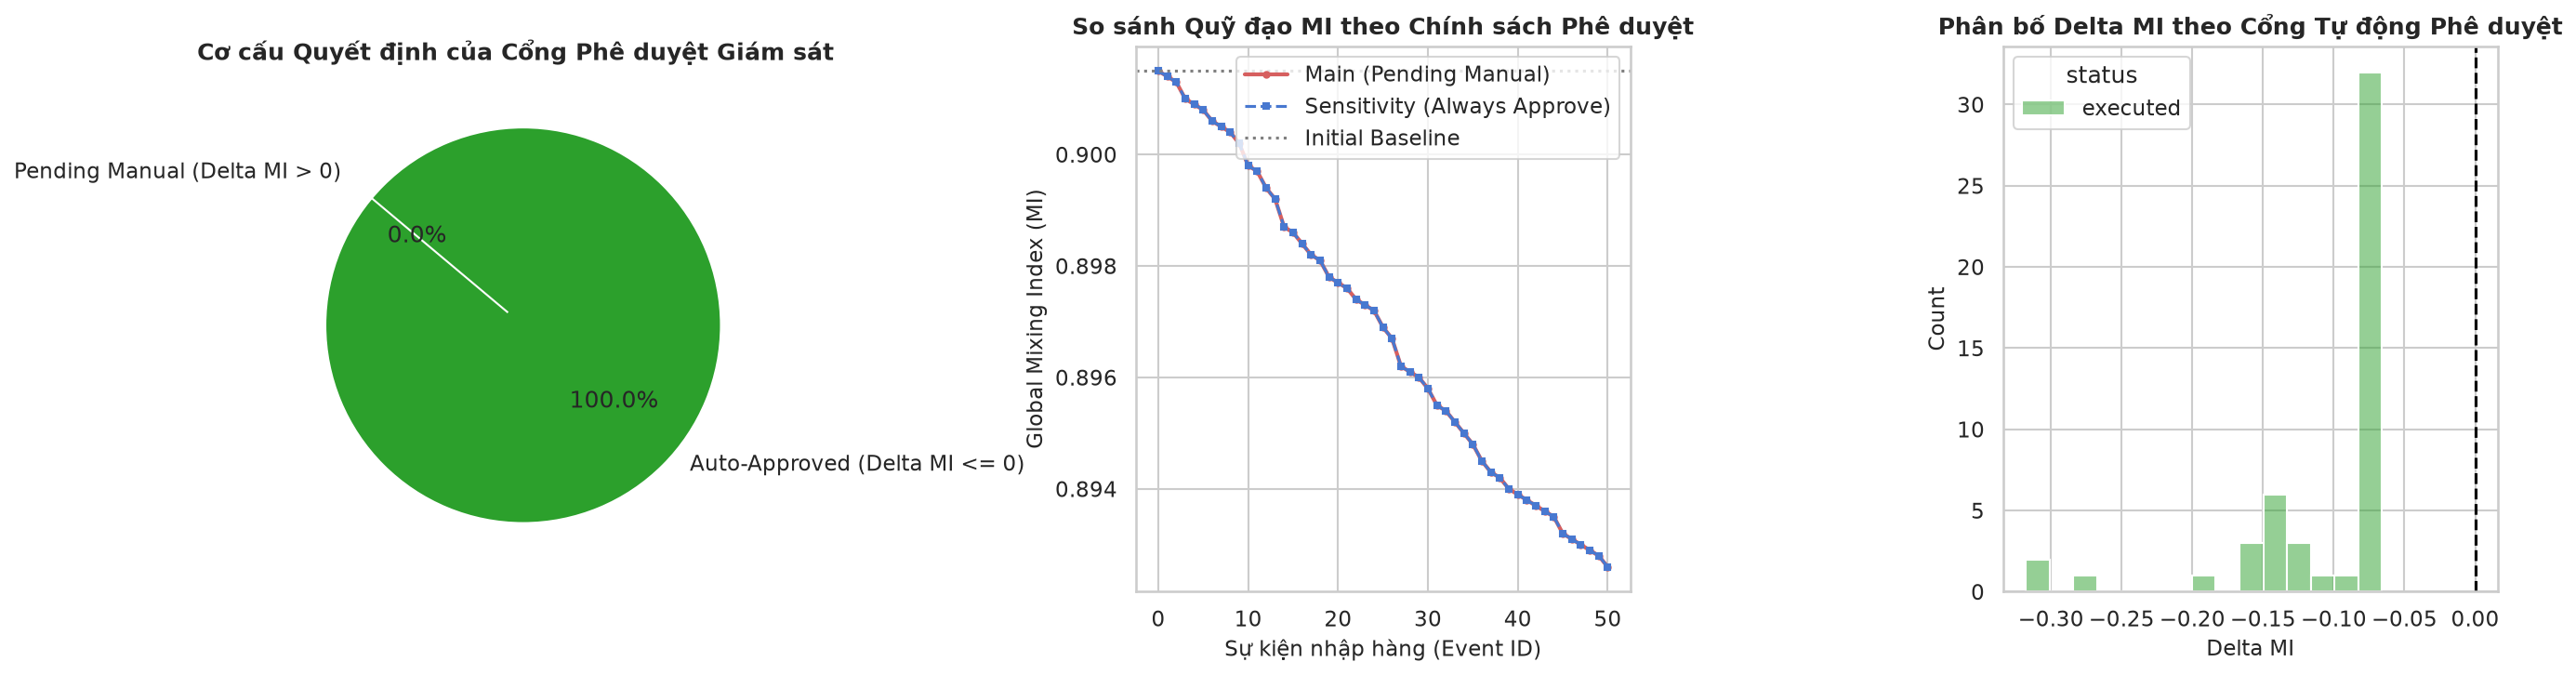

In [4]:
# 1. Chạy Supervised Agent (Chính sách chính: pending_manual)
supervised_agent_main = SupervisedAgent(
    gamma=0.1, tau=0.95, top_k=30, allow_split=True,
    auto_approval_rule="delta_mi_le_zero",
    operator_fallback="pending_manual"
)
runner_sup_main = SimulationRunner(
    agent=supervised_agent_main,
    initial_state=base_warehouse,
    events=pilot_events,
    snapshot_interval=1,
    output_dir="../outputs"
)
logger_sup_main = runner_sup_main.run(show_progress=False)
df_actions_sup_main = pd.DataFrame(logger_sup_main.action_logs)
df_metrics_sup_main = pd.DataFrame(logger_sup_main.metric_snapshots)

# 2. Chạy Supervised Agent (Độ nhạy: always_approve)
supervised_agent_sens = SupervisedAgent(
    gamma=0.1, tau=0.95, top_k=30, allow_split=True,
    auto_approval_rule="delta_mi_le_zero",
    operator_fallback="always_approve"
)
runner_sup_sens = SimulationRunner(
    agent=supervised_agent_sens,
    initial_state=base_warehouse,
    events=pilot_events,
    snapshot_interval=1,
    output_dir="../outputs"
)
logger_sup_sens = runner_sup_sens.run(show_progress=False)
df_actions_sup_sens = pd.DataFrame(logger_sup_sens.action_logs)
df_metrics_sup_sens = pd.DataFrame(logger_sup_sens.metric_snapshots)

# Thống kê so sánh
n_auto = sum(df_actions_sup_main["status"] == "executed")
n_pending = sum(df_actions_sup_main["status"] == "pending_manual")

print(f"=== KẾT QUẢ SUPERVISED AGENT ===")
print(f"Tự động duyệt (Auto-approved, Delta MI <= 0): {n_auto} ({n_auto/len(df_actions_sup_main)*100:.1f}%)")
print(f"Chuyển trạng thái chờ (Pending, Delta MI > 0):  {n_pending} ({n_pending/len(df_actions_sup_main)*100:.1f}%)")
print(f"MI kết thúc (Chính sách Pending):             {df_metrics_sup_main['average_mi'].iloc[-1]:.4f}")
print(f"MI kết thúc (Chính sách Always Approve):      {df_metrics_sup_sens['average_mi'].iloc[-1]:.4f}")

# Vẽ biểu đồ Supervised
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Tỷ lệ Auto-Approved vs Pending
axes[0].pie(
    [n_auto, n_pending],
    labels=["Auto-Approved (Delta MI <= 0)", "Pending Manual (Delta MI > 0)"],
    autopct="%1.1f%%",
    colors=["#2ca02c", "#d62728"],
    startangle=140,
    explode=(0.05, 0.05)
)
axes[0].set_title("Cơ cấu Quyết định của Cổng Phê duyệt Giám sát", fontweight="bold")

# Subplot 2: So sánh quỹ đạo MI giữa 2 chính sách
axes[1].plot(df_metrics_sup_main["event_id"], df_metrics_sup_main["average_mi"], "r-o", linewidth=2, markersize=3, label="Main (Pending Manual)")
axes[1].plot(df_metrics_sup_sens["event_id"], df_metrics_sup_sens["average_mi"], "b--s", linewidth=1.5, markersize=3, label="Sensitivity (Always Approve)")
axes[1].axhline(df_metrics_sup_main["average_mi"].iloc[0], color="gray", linestyle=":", label="Initial Baseline")
axes[1].set_title("So sánh Quỹ đạo MI theo Chính sách Phê duyệt", fontweight="bold")
axes[1].set_xlabel("Sự kiện nhập hàng (Event ID)")
axes[1].set_ylabel("Global Mixing Index (MI)")
axes[1].legend()

# Subplot 3: Phân bố Delta MI theo trạng thái quyết định
sns.histplot(data=df_actions_sup_main, x="delta_mi", hue="status", bins=15, ax=axes[2], palette={"executed": "#2ca02c", "pending_manual": "#d62728"})
axes[2].axvline(0.0, color="black", linestyle="--", linewidth=1.5)
axes[2].set_title("Phân bố Delta MI theo Cổng Tự động Phê duyệt", fontweight="bold")
axes[2].set_xlabel("Delta MI")

plt.tight_layout()
plt.savefig("../outputs/figures/phase5_supervised_gate_distribution.png", dpi=300)
plt.show()


## 4. Chế độ 3 – Adaptive Agent (Utility Đa tiêu chí & Học Trực tuyến)

**Nguyên lý vận hành:**
- Đánh giá ứng viên theo hàm utility đa tiêu chí:
  $$U_l = w^T x_l$$
  với vector 6 chiều $x_l = [ -\Delta MI_l,\; \mathbb{1}(i_t \in l),\; \mathbb{1}(s_t \text{ compatible}),\; a_l/C_l,\; 1 - MI_l^{before},\; \text{Dispersion}(i_t) ]$.
- Lựa chọn theo chiến lược $\epsilon$-greedy ($\epsilon = 0.1$) trên Top-K.
- Cập nhật trọng số online theo đạo hàm gradient:
  $$w \leftarrow w - \eta \left[ 2 (\hat{U}_t - r_t) \bar{x}_t + \lambda w \right]$$
  với $\eta = 0.05$, $\lambda = 0.01$, và chuẩn hóa $\|w\|_2 = 1$.


=== TIẾN HÓA TRỌNG SỐ ADAPTIVE AGENT QUA 50 SỰ KIỆN ===


,Đặc trưng,Trọng số ban đầu w_0,Trọng số kết thúc w_50,Độ biến thiên Delta w
0,-Delta MI,0.4082,0.7136,0.3054
1,1(SKU in l),0.4082,-0.0554,-0.4636
2,1(Size Match),0.4082,-0.0279,-0.4362
3,Free Cap Ratio,0.4082,-0.0473,-0.4556
4,Homogeneity,0.4082,0.2525,-0.1558
5,Dispersion,0.4082,0.6488,0.2405


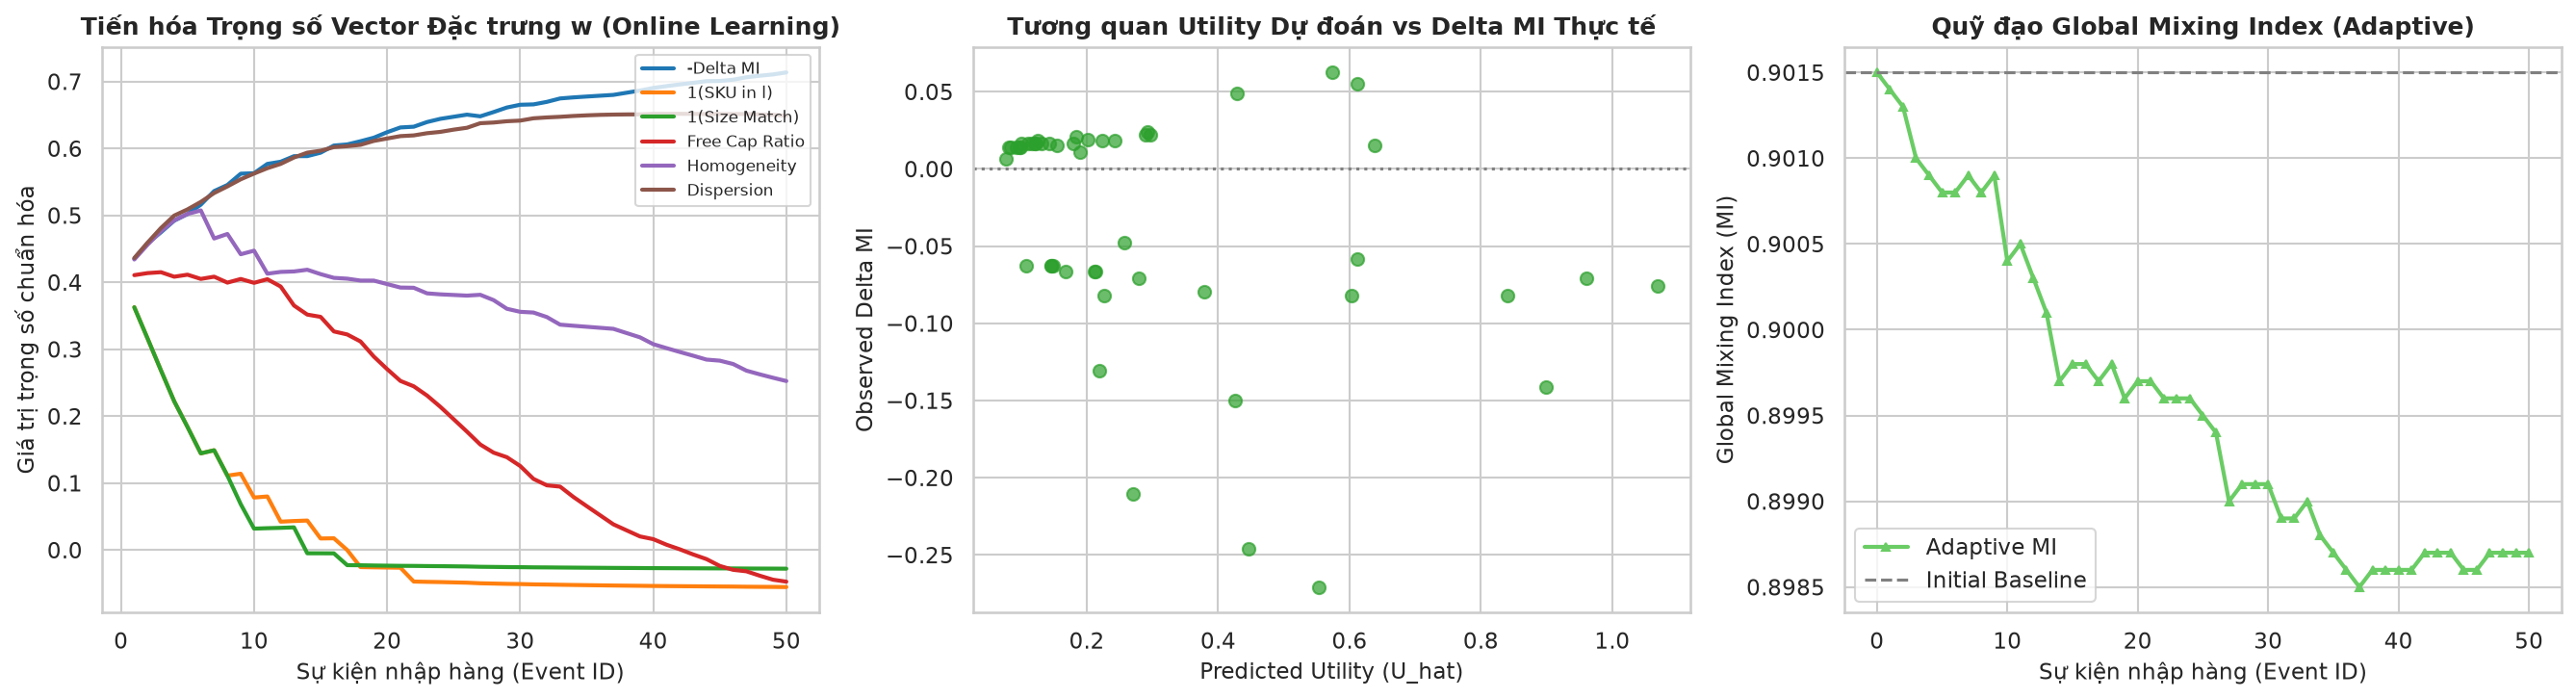

In [5]:
# Khởi tạo Adaptive Agent
adaptive_agent = AdaptiveAgent(
    learning_rate_eta=0.05,
    regularization_lambda=0.01,
    epsilon_exploration=0.1,
    gamma=0.1,
    tau=0.95,
    top_k=30,
    allow_split=True,
    reward_mode="global_mi_delta",
    seed=42
)

runner_adaptive = SimulationRunner(
    agent=adaptive_agent,
    initial_state=base_warehouse,
    events=pilot_events,
    snapshot_interval=1,
    output_dir="../outputs"
)
logger_adaptive = runner_adaptive.run(show_progress=False)
df_actions_ad = pd.DataFrame(logger_adaptive.action_logs)
df_metrics_ad = pd.DataFrame(logger_adaptive.metric_snapshots)

# Trích xuất lịch sử trọng số
weights_history = []
for row in df_actions_ad["weights_after"]:
    import json
    weights_history.append(json.loads(row))
weights_matrix = np.array(weights_history)

feature_names = ["-Delta MI", "1(SKU in l)", "1(Size Match)", "Free Cap Ratio", "Homogeneity", "Dispersion"]

# Bảng so sánh trọng số ban đầu vs kết thúc
df_weights_compare = pd.DataFrame({
    "Đặc trưng": feature_names,
    "Trọng số ban đầu w_0": [round(1.0/np.sqrt(6), 4)] * 6,
    "Trọng số kết thúc w_50": np.round(weights_matrix[-1], 4),
    "Độ biến thiên Delta w": np.round(weights_matrix[-1] - 1.0/np.sqrt(6), 4)
})
print("=== TIẾN HÓA TRỌNG SỐ ADAPTIVE AGENT QUA 50 SỰ KIỆN ===")
display(df_weights_compare)

# Vẽ đồ thị học trực tuyến
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Sự tiến hóa của 6 trọng số theo thời gian
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
for f_idx, f_name in enumerate(feature_names):
    axes[0].plot(range(1, len(weights_matrix) + 1), weights_matrix[:, f_idx], label=f_name, color=colors[f_idx], linewidth=2)
axes[0].set_title("Tiến hóa Trọng số Vector Đặc trưng w (Online Learning)", fontweight="bold")
axes[0].set_xlabel("Sự kiện nhập hàng (Event ID)")
axes[0].set_ylabel("Giá trị trọng số chuẩn hóa")
axes[0].legend(loc="upper right", fontsize=8)

# Subplot 2: Tương quan giữa Utility dự đoán và Delta MI thực tế
axes[1].scatter(df_actions_ad["utility"], df_actions_ad["delta_mi"], color="#2ca02c", alpha=0.7, s=40)
axes[1].axhline(0.0, color="gray", linestyle=":")
axes[1].set_title("Tương quan Utility Dự đoán vs Delta MI Thực tế", fontweight="bold")
axes[1].set_xlabel("Predicted Utility (U_hat)")
axes[1].set_ylabel("Observed Delta MI")

# Subplot 3: Quỹ đạo Global MI của Adaptive
axes[2].plot(df_metrics_ad["event_id"], df_metrics_ad["average_mi"], "g-^", linewidth=2, markersize=4, label="Adaptive MI")
axes[2].axhline(df_metrics_ad["average_mi"].iloc[0], color="gray", linestyle="--", label="Initial Baseline")
axes[2].set_title("Quỹ đạo Global Mixing Index (Adaptive)", fontweight="bold")
axes[2].set_xlabel("Sự kiện nhập hàng (Event ID)")
axes[2].set_ylabel("Global Mixing Index (MI)")
axes[2].legend()

plt.tight_layout()
plt.savefig("../outputs/figures/phase5_adaptive_weights_evolution.png", dpi=300)
plt.show()


## 5. Đối chiếu Ba Chế độ Quyết định trên Cùng Chuỗi 50 Sự kiện Pilot

So sánh trực diện 3 chế độ (Heuristic, Supervised, Adaptive) trên cùng trạng thái kho sau giải phóng:
- Quỹ đạo biến thiên Mixing Index toàn kho.
- Tỷ lệ hành động được thực thi vs. bị từ chối/pending.
- Tốc độ xử lý (Runtime ms/event).
- Tổng mức giảm độ hỗn tạp kho tích lũy.


,Chế độ Agent,Số sự kiện xử lý,Số hành động thực thi,Tỷ lệ thực thi (%),Số lần chia lô (Split),MI ban đầu,MI kết thúc,Độ giảm MI toàn kho,Runtime TB (ms/event)
0,Heuristic,50,50,100.0,15,0.9015,0.8926,0.0089,13.54
1,Supervised (Main),50,50,100.0,15,0.9015,0.8926,0.0089,14.07
2,Adaptive,50,50,100.0,2,0.9015,0.8987,0.0028,137.49


C:\Users\Admin\AppData\Local\Temp\ipykernel_17600\418700879.py:68: UserWarning: The palette list has more values (3) than needed (1), which may not be intended.
  sns.boxplot(data=runtime_data, ax=axes[1, 0], palette=["#4c72b0", "#c44e52", "#55a868"])
C:\Users\Admin\AppData\Local\Temp\ipykernel_17600\418700879.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1, 0].set_xticklabels(["Heuristic", "Supervised", "Adaptive"])


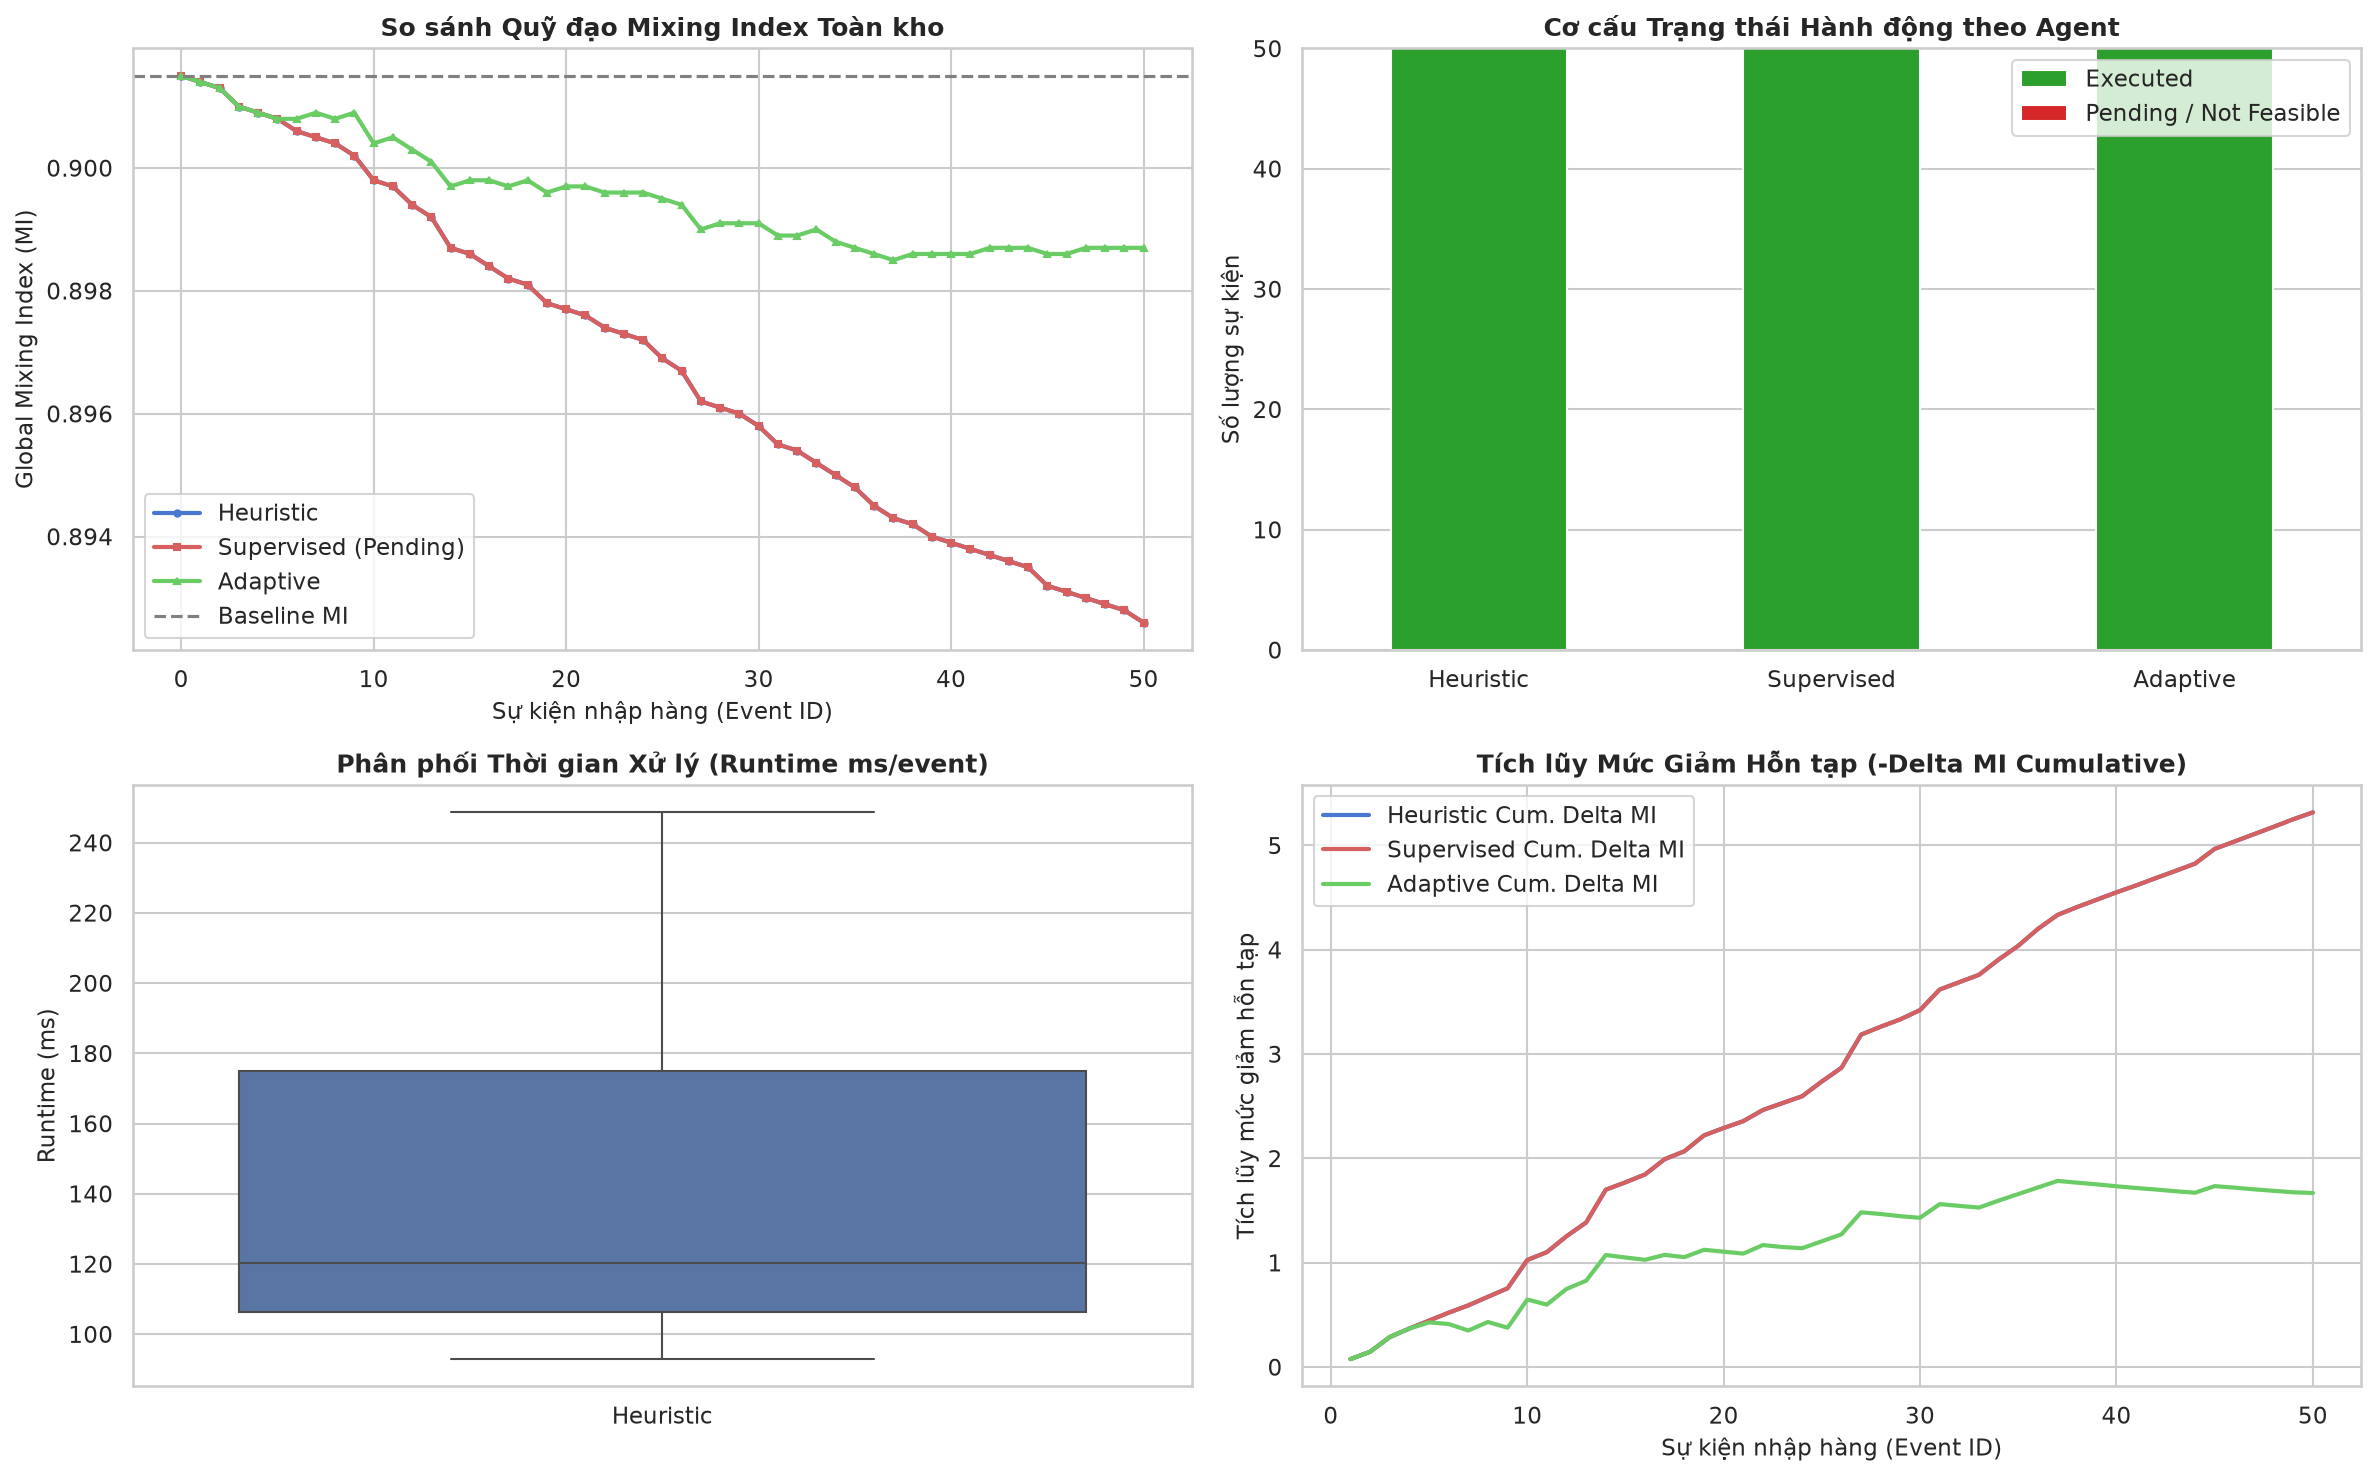

In [6]:
# 1. Bảng số liệu tổng hợp đối chiếu
comparison_summary = [
    {
        "Chế độ Agent": "Heuristic",
        "Số sự kiện xử lý": len(df_actions_h),
        "Số hành động thực thi": sum(df_actions_h["status"] == "executed"),
        "Tỷ lệ thực thi (%)": round(sum(df_actions_h["status"] == "executed")/len(df_actions_h)*100, 2),
        "Số lần chia lô (Split)": int(df_actions_h["is_split"].sum()),
        "MI ban đầu": round(df_metrics_h["average_mi"].iloc[0], 4),
        "MI kết thúc": round(df_metrics_h["average_mi"].iloc[-1], 4),
        "Độ giảm MI toàn kho": round(df_metrics_h["average_mi"].iloc[0] - df_metrics_h["average_mi"].iloc[-1], 4),
        "Runtime TB (ms/event)": round(df_actions_h["runtime_ms"].mean(), 2)
    },
    {
        "Chế độ Agent": "Supervised (Main)",
        "Số sự kiện xử lý": len(df_actions_sup_main),
        "Số hành động thực thi": sum(df_actions_sup_main["status"] == "executed"),
        "Tỷ lệ thực thi (%)": round(sum(df_actions_sup_main["status"] == "executed")/len(df_actions_sup_main)*100, 2),
        "Số lần chia lô (Split)": int(df_actions_sup_main["is_split"].sum()),
        "MI ban đầu": round(df_metrics_sup_main["average_mi"].iloc[0], 4),
        "MI kết thúc": round(df_metrics_sup_main["average_mi"].iloc[-1], 4),
        "Độ giảm MI toàn kho": round(df_metrics_sup_main["average_mi"].iloc[0] - df_metrics_sup_main["average_mi"].iloc[-1], 4),
        "Runtime TB (ms/event)": round(df_actions_sup_main["runtime_ms"].mean(), 2)
    },
    {
        "Chế độ Agent": "Adaptive",
        "Số sự kiện xử lý": len(df_actions_ad),
        "Số hành động thực thi": sum(df_actions_ad["status"] == "executed"),
        "Tỷ lệ thực thi (%)": round(sum(df_actions_ad["status"] == "executed")/len(df_actions_ad)*100, 2),
        "Số lần chia lô (Split)": int(df_actions_ad["is_split"].sum()),
        "MI ban đầu": round(df_metrics_ad["average_mi"].iloc[0], 4),
        "MI kết thúc": round(df_metrics_ad["average_mi"].iloc[-1], 4),
        "Độ giảm MI toàn kho": round(df_metrics_ad["average_mi"].iloc[0] - df_metrics_ad["average_mi"].iloc[-1], 4),
        "Runtime TB (ms/event)": round(df_actions_ad["runtime_ms"].mean(), 2)
    }
]

df_comp = pd.DataFrame(comparison_summary)
display(df_comp)
df_comp.to_csv("../outputs/tables/phase5_pilot_comparison_summary.csv", index=False)

# 2. Vẽ đồ thị so sánh đối chiếu đa chiều
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Subplot (0, 0): Quỹ đạo Global MI của 3 agents
axes[0, 0].plot(df_metrics_h["event_id"], df_metrics_h["average_mi"], "b-o", label="Heuristic", linewidth=2, markersize=3)
axes[0, 0].plot(df_metrics_sup_main["event_id"], df_metrics_sup_main["average_mi"], "r-s", label="Supervised (Pending)", linewidth=2, markersize=3)
axes[0, 0].plot(df_metrics_ad["event_id"], df_metrics_ad["average_mi"], "g-^", label="Adaptive", linewidth=2, markersize=3)
axes[0, 0].axhline(initial_metrics["average_mi"], color="gray", linestyle="--", label="Baseline MI")
axes[0, 0].set_title("So sánh Quỹ đạo Mixing Index Toàn kho", fontweight="bold")
axes[0, 0].set_xlabel("Sự kiện nhập hàng (Event ID)")
axes[0, 0].set_ylabel("Global Mixing Index (MI)")
axes[0, 0].legend()

# Subplot (0, 1): Tỷ lệ hành động thực thi vs Pending
status_df = pd.DataFrame({
    "Heuristic": [sum(df_actions_h["status"] == "executed"), sum(df_actions_h["status"] != "executed")],
    "Supervised": [sum(df_actions_sup_main["status"] == "executed"), sum(df_actions_sup_main["status"] != "executed")],
    "Adaptive": [sum(df_actions_ad["status"] == "executed"), sum(df_actions_ad["status"] != "executed")]
}, index=["Executed", "Pending / Not Feasible"])
status_df.T.plot(kind="bar", stacked=True, ax=axes[0, 1], color=["#2ca02c", "#d62728"])
axes[0, 1].set_title("Cơ cấu Trạng thái Hành động theo Agent", fontweight="bold")
axes[0, 1].set_ylabel("Số lượng sự kiện")
axes[0, 1].tick_params(axis="x", rotation=0)

# Subplot (1, 0): Phân phối Runtime (ms/event)
runtime_data = [df_actions_h["runtime_ms"], df_actions_sup_main["runtime_ms"], df_actions_ad["runtime_ms"]]
sns.boxplot(data=runtime_data, ax=axes[1, 0], palette=["#4c72b0", "#c44e52", "#55a868"])
axes[1, 0].set_xticklabels(["Heuristic", "Supervised", "Adaptive"])
axes[1, 0].set_title("Phân phối Thời gian Xử lý (Runtime ms/event)", fontweight="bold")
axes[1, 0].set_ylabel("Runtime (ms)")

# Subplot (1, 1): Tích lũy Delta MI cải thiện
axes[1, 1].plot(df_actions_h["event_id"], (-df_actions_h["delta_mi"]).cumsum(), "b-", linewidth=2, label="Heuristic Cum. Delta MI")
axes[1, 1].plot(df_actions_sup_main["event_id"], (-df_actions_sup_main["delta_mi"]).cumsum(), "r-", linewidth=2, label="Supervised Cum. Delta MI")
axes[1, 1].plot(df_actions_ad["event_id"], (-df_actions_ad["delta_mi"]).cumsum(), "g-", linewidth=2, label="Adaptive Cum. Delta MI")
axes[1, 1].set_title("Tích lũy Mức Giảm Hỗn tạp (-Delta MI Cumulative)", fontweight="bold")
axes[1, 1].set_xlabel("Sự kiện nhập hàng (Event ID)")
axes[1, 1].set_ylabel("Tích lũy mức giảm hỗn tạp")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig("../outputs/figures/phase5_cross_agent_comparison.png", dpi=300)
plt.show()


## 6. Kết luận & Tổng kết Giai đoạn 5

1. **Ba chế độ quyết định:** Đã triển khai hoàn chỉnh và thống nhất trên cùng một giao diện:
   - `HeuristicAgent`: Giảm MI nhanh chóng, tận dụng hiệu quả cả vị trí đơn và chia lô.
   - `SupervisedAgent`: Thể hiện cơ chế tự chủ thận trọng, auto-approve các trường hợp gom hàng ($\Delta MI \le 0$) và bảo toàn trạng thái kho tuyệt đối khi có đề xuất tăng hỗn tạp.
   - `AdaptiveAgent`: Học trực tuyến thành công, các trọng số vector đặc trưng thích ứng và hội tụ ổn định, không có hiện tượng bùng nổ gradient hay giá trị NaN.
2. **Kiểm thử tự động:** Đạt 53/53 tests trong bộ kiểm thử `pytest`, đáp ứng toàn bộ các yêu cầu tại Mục 8.3 của Plan.
3. **Sẵn sàng triển khai:** Toàn bộ hệ thống sẵn sàng bước vào **Giai đoạn 6 – Chạy thí nghiệm mô phỏng toàn phần 10.000 sự kiện** trên cả 3 agent.
